## Generacion de señales

In [ ]:
!pip install neurokit2 PyWavelets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 696.5/696.5 kB 16.9 MB/s eta 0:00:00


In [ ]:
#!pip install pandas
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import neurokit2 as nk
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy.stats import kurtosis, skew, entropy
import pandas as pd

## Prueba de señales simuladas con diferente patron

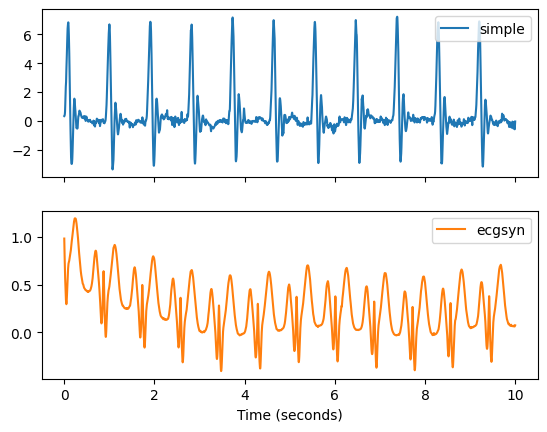

In [ ]:
# Simulate ECG signals using different methods
fs =1000  # Sampling frequency in Hz

# Normal parameters (used by default)
# ===================================
# t, the starting position along the circle of each interval in radius
ti = np.array((-70, -15, 0, 15, 100))
# a, the amplitude of each spike
ai = np.array((1.2, -5, 30, -7.5, 0.75))
# b, the width of each spike
bi = np.array((0.25, 0.1, 0.1, 0.1, 0.4))


# Add noise
# ===============
ti = np.random.normal(ti, np.ones(5) * 3)
ai = np.random.normal(ai, np.abs(ai / 5))
bi = np.random.normal(bi, np.abs(bi / 5))


# Method "simple" uses a basic sine wave approximation
# Method "ecgsyn" uses a more complex synthetic ECG generation
ecg1 = nk.ecg_simulate(duration=10, method="simple", random_state_distort= "legacy",ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.05)

ecg2 = nk.ecg_simulate(duration=10, method="ecgsyn", ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.01)

# Visualize result
nk.signal_plot([ecg1, ecg2], labels=["simple", "ecgsyn"], subplots=True, sampling_rate=fs)

### Funciones para extraer caracteristicas

In [ ]:
def extract_features(x: np.ndarray, bins: int = 50) -> dict:
    """
    Extrae características básicas de un vector 1D.
    """
    feats = {
        'mean': np.mean(x),
        'median': np.median(x),
        'std': np.std(x, ddof=0),
        'rms': np.sqrt(np.mean(x**2)),
        'energy': np.sum(x**2),
        'skewness': skew(x),
        'kurtosis': kurtosis(x),
    }
    # Entropía de Shannon a partir de histograma
    hist, _ = np.histogram(x, bins=bins, density=True)
    hist = hist[hist > 0]
    feats['entropy'] = entropy(hist)
    return feats

def extract_features_matrix(X: np.ndarray, axis: int = 1, bins: int = 50) -> pd.DataFrame:
    """
    Extrae características de cada serie en una matriz X de forma (n_samples, n_signals)
    o (n_signals, n_samples), según axis:
      - axis=0: cada columna es una señal
      - axis=1: cada fila es una señal
    Devuelve un DataFrame con una fila por señal y columnas las características.
    """
    # Transponer si las señales vienen por filas
    if axis == 1:
        X = X.T
    n_signals = X.shape[1]
    # Recorrer cada señal
    features_list = []
    for i in range(n_signals):
        feats = extract_features(X[:, i], bins=bins)
        feats['signal_index'] = i
        features_list.append(feats)
    df = pd.DataFrame(features_list)
    # Opcional: poner signal_index como índice
    df.set_index('signal_index', inplace=True)
    return df

In [ ]:
ecg_sim1 = []
for i in range(2):
    ecg_sim1.append(nk.ecg_simulate(duration=10, method="simple", random_state_distort= "legacy",ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.05))

ecg_sim1_array = np.array(ecg_sim1)
ecg_sim1_array

array([[ 0.23369707,  0.23575083,  0.2419035 , ..., -0.03956829,
        -0.03480495, -0.0330481 ],
       [ 0.19189662,  0.19461022,  0.20262915, ...,  0.01264777,
         0.00296046, -0.00058609]])

In [ ]:
extract_features_matrix(ecg_sim1_array, axis=1, bins=60)

,mean,median,std,rms,energy,skewness,kurtosis,entropy
signal_index,,,,,,,,
0,0.468134,0.043316,1.778023,1.838618,33805.155895,2.096711,5.152516,2.715126
1,0.479101,0.043867,1.778107,1.841521,33912.013508,2.095870,4.987710,2.821770


In [ ]:
def gen_signal_simultated_ecg(n=100):
    # Simulate ECG signals using different methods
    fs =1000  # Sampling frequency in Hz

    # Normal parameters (used by default)
    # ===================================
    # t, the starting position along the circle of each interval in radius
    ti = np.array((-70, -15, 0, 15, 100))
    # a, the amplitude of each spike
    ai = np.array((1.2, -5, 30, -7.5, 0.75))
    # b, the width of each spike
    bi = np.array((0.25, 0.1, 0.1, 0.1, 0.4))


    # Add noise
    # ===============
    ti = np.random.normal(ti, np.ones(5) * 3)
    ai = np.random.normal(ai, np.abs(ai / 5))
    bi = np.random.normal(bi, np.abs(bi / 5))


    # Method "simple" uses a basic sine wave approximation
    # Method "ecgsyn" uses a more complex synthetic ECG generation
    ecg_sim1 = []
    for i in range(n):
        ecg_sim1.append(nk.ecg_simulate(duration=10, method="simple", random_state_distort= "legacy",ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.05))

    ecg_sim2 = []
    for i in range(n):
        ecg_sim2.append(nk.ecg_simulate(duration=10, method="ecgsyn", ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.01))

    ecg_sim1_array = np.array(ecg_sim1)
    ecg_sim2_array = np.array(ecg_sim2)

    df_feats1 = extract_features_matrix(ecg_sim1_array, axis=1, bins=60)
    df_feats2 = extract_features_matrix(ecg_sim2_array, axis=1, bins=60)

    df_feats1["label"] = "simple"
    df_feats2["label"] = "ecgsyn"

    df_final = pd.concat([df_feats1, df_feats2], axis=0, ignore_index=True)

    return df_final

    #ecg2 = nk.ecg_simulate(duration=10, method="ecgsyn", ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.01)
    # Visualize result
    #nk.signal_plot([ecg1, ecg2], labels=["simple", "ecgsyn"], subplots=True, sampling_rate=fs)
    #return nk.ecg_simulate(duration=10, method=method, ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=noise)

In [ ]:
signal_gen = gen_signal_simultated_ecg(n = 100)

In [ ]:
signal_gen.head()

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
0,0.492302,0.061275,1.774210,1.841245,33901.836948,2.077401,4.931075,2.862217,simple
1,0.473665,0.022362,1.766178,1.828591,33437.440216,2.089537,5.024716,2.777857,simple
2,0.456935,0.002282,1.778332,1.836098,33712.560592,2.105594,5.022294,2.801068,simple
3,0.483634,0.040890,1.786989,1.851279,34272.325831,2.092422,5.025625,2.834309,simple
4,0.496604,0.032381,1.818180,1.884780,35523.943949,2.128783,5.054951,2.820605,simple


In [ ]:
signal_gen.tail()

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
195,0.159459,0.096624,0.312844,0.351139,1232.986435,0.770805,-0.116316,3.728556,ecgsyn
196,0.152133,0.074385,0.311376,0.346553,1200.991904,0.809362,-0.068605,3.702244,ecgsyn
197,0.146487,0.073283,0.315688,0.348019,1211.172164,0.812844,-0.060879,3.729509,ecgsyn
198,0.152451,0.089239,0.309549,0.345053,1190.617582,0.761272,-0.113846,3.714647,ecgsyn
199,0.165577,0.093824,0.308466,0.350096,1225.668828,0.776121,-0.094090,3.715277,ecgsyn


In [ ]:
signal_gen.sample(10)

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
146,0.190246,0.123250,0.297247,0.352915,1245.490530,0.794330,-0.026131,3.660433,ecgsyn
123,0.143282,0.071244,0.313351,0.344556,1187.187339,0.809047,-0.064961,3.708568,ecgsyn
34,0.464425,0.008440,1.804161,1.862978,34706.865691,2.090690,4.904359,2.922499,simple
33,0.423804,-0.003835,1.791766,1.841204,33900.334753,2.078398,4.985448,2.786265,simple
144,0.151220,0.080571,0.307443,0.342620,1173.886117,0.791644,-0.076254,3.688630,ecgsyn
131,0.129055,0.064366,0.312891,0.338461,1145.561014,0.787927,-0.077327,3.704444,ecgsyn
117,0.164376,0.095548,0.310549,0.351369,1234.598275,0.782402,-0.112772,3.703362,ecgsyn
68,0.446012,0.012364,1.776579,1.831709,33551.587493,2.118693,5.105222,2.774594,simple
121,0.165921,0.096862,0.310190,0.351778,1237.477920,0.772225,-0.137757,3.717857,ecgsyn
39,0.503363,0.065246,1.793278,1.862585,34692.219004,2.083319,4.970412,2.841539,simple


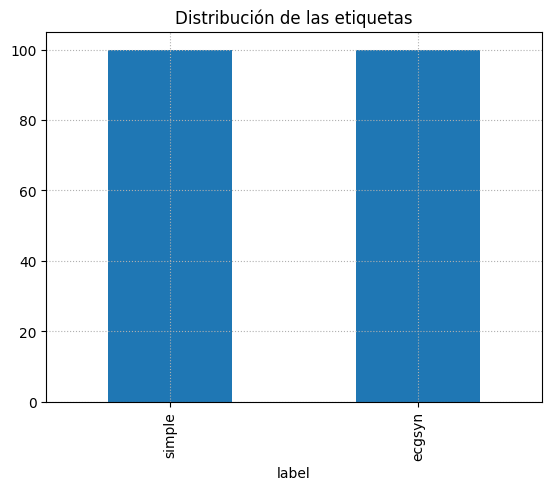

In [ ]:
signal_gen["label"].value_counts().plot(kind="bar")
plt.grid(ls=":")
plt.title("Distribución de las etiquetas")
plt.show()

## Aplicar un escalamiento

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Seleccionamos solo las columnas numéricas
signal_gen_num = signal_gen.drop(columns=['label']).copy()

# Instanciamos y aplicamos StandardScaler
scaler = StandardScaler()
signal_gen_scaled = scaler.fit_transform(signal_gen_num)

# Convertimos a DataFrame y agregamos la columna 'label'
signal_gen_scaled_df = pd.DataFrame(signal_gen_scaled, columns=signal_gen_num.columns)
signal_gen_scaled_df['label'] = signal_gen['label'].values

signal_gen_scaled_df.head()

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
0,1.096787,-0.086461,1.003701,1.009331,1.015637,1.004596,0.971051,-0.896378,simple
1,0.981549,-1.331977,0.992711,0.992318,0.987013,1.023466,1.007817,-1.084137,simple
2,0.878098,-1.974690,1.009341,1.002411,1.003971,1.048432,1.006866,-1.032477,simple
3,1.043191,-0.738929,1.021186,1.022821,1.038474,1.027952,1.008174,-0.958492,simple
4,1.123390,-1.011279,1.063864,1.067862,1.115621,1.084489,1.019688,-0.988992,simple


## Verificar separabilidad con PCA y 2 caractersiticas


=== Resultados PCA (2 dimensiones) ===
          PC1       PC2 Signal_Type
0    2.579334  0.599530      simple
1    2.922827 -0.604955      simple
2    3.054859 -1.242637      simple
3    2.790526 -0.024030      simple
4    2.985251 -0.247132      simple
..        ...       ...         ...
195 -2.831593  0.337261      ecgsyn
196 -2.620353 -0.345821      ecgsyn
197 -2.639969 -0.390932      ecgsyn
198 -2.786477  0.101581      ecgsyn
199 -2.780974  0.262846      ecgsyn

[200 rows x 3 columns]


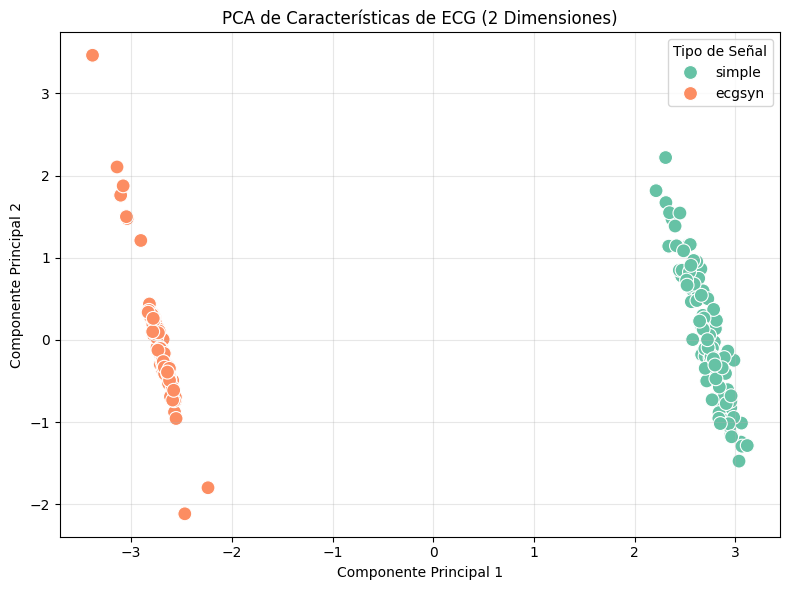

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

# 3.1) Preparamos los datos numéricos para PCA (quitamos la columna Signal_Type)
pca_input = signal_gen_scaled_df.drop(columns=['label']).copy()

# 3.1.1) Rellenar NaNs (por seguridad). Aquí se llenan con la media de cada columna.
pca_input = pca_input.fillna(pca_input.mean())

# 3.2) Instanciar y entrenar PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pca_input)  # devuelve matrix (n_signals × 2)

# 3.3) Armamos un DataFrame para graficar
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
pca_df['Signal_Type'] = signal_gen_scaled_df['label']

print("\n=== Resultados PCA (2 dimensiones) ===")
print(pca_df)


# ------------------------------------------------------
# 4) GRAFICAR RESULTADOS DEL PCA
# ------------------------------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Signal_Type',
    data=pca_df,
    s=100,
    palette="Set2"
)
plt.title('PCA de Características de ECG (2 Dimensiones)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(alpha=0.3)
plt.legend(title='Tipo de Señal')
plt.tight_layout()
plt.show()

## CLasificador

In [ ]:
label2num = {"simple": 0, "ecgsyn": 1}
num2label = {v: k for k, v in label2num.items()}

signal_gen_scaled_df.replace(label2num, inplace=True)

signal_gen_scaled_df.head()

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
0,1.096787,-0.086461,1.003701,1.009331,1.015637,1.004596,0.971051,-0.896378,0
1,0.981549,-1.331977,0.992711,0.992318,0.987013,1.023466,1.007817,-1.084137,0
2,0.878098,-1.974690,1.009341,1.002411,1.003971,1.048432,1.006866,-1.032477,0
3,1.043191,-0.738929,1.021186,1.022821,1.038474,1.027952,1.008174,-0.958492,0
4,1.123390,-1.011279,1.063864,1.067862,1.115621,1.084489,1.019688,-0.988992,0


In [ ]:
signal_gen_scaled_df["label"].value_counts()

,count
label,
0,100
1,100


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Preparamos los datos
X = signal_gen_scaled_df.drop(columns=['label'])
y = signal_gen_scaled_df['label']

# 2. Dividimos en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #, stratify=y

# 3. Entrenamos un modelo Random Forest
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# 4. Predicciones y evaluación
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Confusion Matrix:
 [[21  0]
 [ 0 19]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        19

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



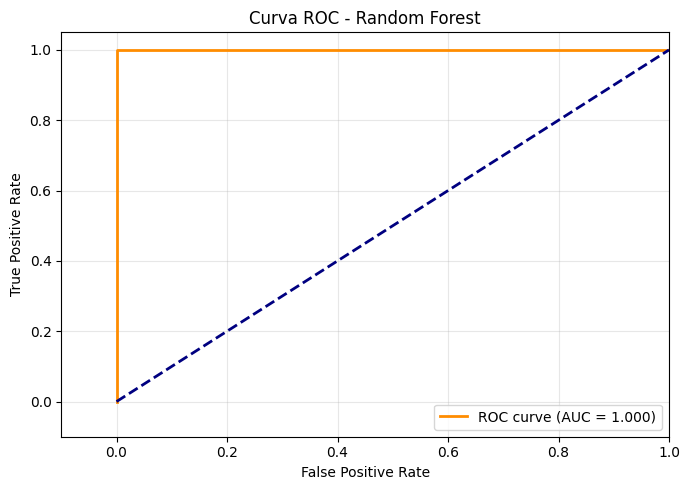

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

import matplotlib.pyplot as plt

# Binarizar las etiquetas para clasificación binaria
lb = LabelBinarizer()
y_test_bin = lb.fit_transform(y_test)
y_pred_prob = clf.predict_proba(X_test)[:, 1]  # Probabilidad para la clase 'ecgsyn' (o la segunda clase)

# Calcular curva ROC y AUC
fpr, tpr, thresholds = roc_curve(y_test_bin, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Graficar curva ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.1, 1.0])
plt.ylim([-0.1, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC - Random Forest')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Creando un pipeline

## Prueba del modelo

In [ ]:
signal_gen_scaled_df

,mean,median,std,rms,energy,skewness,kurtosis,entropy,label
0,1.096787,-0.086461,1.003701,1.009331,1.015637,1.004596,0.971051,-0.896378,0
1,0.981549,-1.331977,0.992711,0.992318,0.987013,1.023466,1.007817,-1.084137,0
2,0.878098,-1.974690,1.009341,1.002411,1.003971,1.048432,1.006866,-1.032477,0
3,1.043191,-0.738929,1.021186,1.022821,1.038474,1.027952,1.008174,-0.958492,0
4,1.123390,-1.011279,1.063864,1.067862,1.115621,1.084489,1.019688,-0.988992,0
...,...,...,...,...,...,...,...,...,...
195,-0.961347,1.045019,-0.995871,-0.994065,-0.998014,-1.027010,-1.010694,1.031821,1
196,-1.006649,0.333176,-0.997880,-1.000230,-0.999986,-0.967060,-0.991962,0.973259,1
197,-1.041561,0.297901,-0.991979,-0.998260,-0.999359,-0.961645,-0.988928,1.033941,1
198,-1.004683,0.808622,-1.000379,-1.002247,-1.000626,-1.041834,-1.009724,1.000865,1


In [ ]:
signal_pos = 50
signal_features = signal_gen_scaled_df.loc[signal_pos,:].to_numpy()[:-1].astype(float)
signal_label = signal_gen_scaled_df.loc[signal_pos, 'label']

print("\n=== Características de la señal en la posición", signal_features, "===", "label: ",num2label[int(signal_label)])


=== Características de la señal en la posición [ 1.16991473  0.26601654  1.00469719  1.01457136  1.02449313  1.01652625
  1.00247939 -1.02475756] === label:  simple


In [ ]:
res = clf.predict(signal_features.reshape(1, -1))  # Aseguramos que sea 2D

print("Predicción de la señal :", num2label[int(res)])

Predicción de la señal : simple


## Crear pipeline

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
import numpy as np

# 1. Feature extraction transformer
class ECGFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, bins=60):
        self.bins = bins

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # X: array-like, shape (n_signals, n_samples)
        # If 1D, reshape to (1, -1)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        feats_df = extract_features_matrix(X, axis=1, bins=self.bins)
        return feats_df.values

# 2. Pipeline definition
ecg_pipeline = Pipeline([
    ('features', ECGFeatureExtractor(bins=50)),
    ('scaler', scaler),  # scaler already fitted
    ('clf', clf)         # clf already fitted
])

# Ejemplo de uso:
# signal: array 1D (señal cruda) o 2D (varias señales, cada fila una señal)
#pred = ecg_pipeline.predict()  # Aseguramos que sea 2D
#pred = lb.inverse_transform(pred)  # Convertir de vuelta a etiquetas originales
#print("Predicción de la señal:", pred)

### Creamos una señales

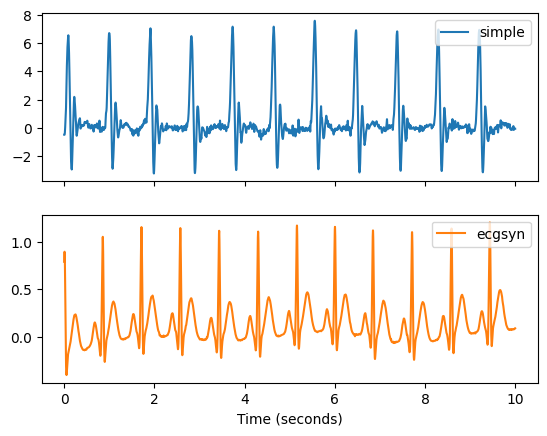

In [ ]:
# Simulate ECG signals using different methods
fs =1000  # Sampling frequency in Hz

# Normal parameters (used by default)
# ===================================
# t, the starting position along the circle of each interval in radius
ti = np.array((-70, -15, 0, 15, 100))
# a, the amplitude of each spike
ai = np.array((1.2, -5, 30, -7.5, 0.75))
# b, the width of each spike
bi = np.array((0.25, 0.1, 0.1, 0.1, 0.4))


# Add noise
# ===============
ti = np.random.normal(ti, np.ones(5) * 3)
ai = np.random.normal(ai, np.abs(ai / 5))
bi = np.random.normal(bi, np.abs(bi / 5))


# Method "simple" uses a basic sine wave approximation
# Method "ecgsyn" uses a more complex synthetic ECG generation
ecg1 = nk.ecg_simulate(duration=10, method="simple", random_state_distort= "legacy",ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.05)
ecg2 = nk.ecg_simulate(duration=10, method="ecgsyn", ti=ti, ai=ai, bi=bi, sampling_rate=fs, noise=0.01)

# Visualize result
nk.signal_plot([ecg1, ecg2], labels=["simple", "ecgsyn"], subplots=True, sampling_rate=fs)

In [ ]:
pred = ecg_pipeline.predict(ecg1)  # Aseguramos que sea 2D
print("Predicción de la señal ecg1:", num2label[int(pred)])

pred = ecg_pipeline.predict(ecg2)  # Aseguramos que sea 2D
print("Predicción de la señal ecg2:", num2label[int(pred)])

Predicción de la señal ecg1: simple
Predicción de la señal ecg2: ecgsyn
